# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [24]:
#Question1
import random

class Card:
    def __init__(self, suit, rank):
        self.suit= suit
        self.rank= rank

    def __str__(self):
        return str(self.rank) + " of " + self.suit


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks= num_decks
        self.cards= []
        self.make_deck()

    def make_deck(self):
        self.cards= []
        suits= ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks= ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        for i in range(self.num_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(suit, rank))

        self.shuffle()

    def shuffle(self):
        random.shuffle(self.cards)
        position= random.randint(1, len(self.cards) - 1)
        self.cards.insert(position, "Plastic")

    def draw(self):
        if len(self.cards) == 0:
            self.make_deck()

        card = self.cards.pop()

        if card == "Plastic":
            self.make_deck()
            return self.draw()

        return card


In [25]:
#Test
deck = Deck(6)

print("Total cards:", len(deck.cards))

for i in range(5):
    print(deck.draw())

print("Cards left:", len(deck.cards))


Total cards: 313
Q of Spades
A of Hearts
10 of Hearts
K of Diamonds
Q of Hearts
Cards left: 308


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [26]:
# Question 3
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def get_value(self):
        pass

    def clear(self):
        pass


class Strategy:
    def __init__(self, name):
        self.name = name

    def choose_action(self, hand, dealer_card):
        pass


class Player:
    def __init__(self, name, chips, strategy):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.strategy = strategy

    def place_bet(self, amount):
        pass

    def decide(self, dealer_card):
        pass


class Dealer:
    def __init__(self):
        self.hand = Hand()

    def hit_or_stand(self):
        pass

    def clear_hand(self):
        pass


class BlackjackGame:
    def __init__(self, players):
        self.deck = Deck(6)
        self.players = players
        self.dealer = Dealer()

    def play_round(self):
        pass

    def simulate(self, rounds):
        pass


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [27]:
#Question 4
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def get_value(self):
        total = 0
        aces = 0

        for card in self.cards:
            if card.rank in ["J", "Q", "K"]:
                total += 10
            elif card.rank == "A":
                total += 11
                aces += 1
            else:
                total += int(card.rank)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def clear(self):
        self.cards = []


class Strategy:
    def __init__(self, name):
        self.name = name

    def choose_action(self, hand, dealer_card):
        if self.name == "human":
            choice = input("Hit or stand? (h/s): ").lower()

            while choice not in ["h", "s"]:
                choice = input("Enter h or s: ").lower()

            return choice

        return "s"


class Player:
    def __init__(self, name, chips, strategy):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.strategy = strategy

    def place_bet(self, amount):
        if amount > 0 and amount <= self.chips:
            self.chips -= amount
            return amount
        else:
            print("Not enough chips or invalid bet")
            return 0

    def decide(self, dealer_card):
        return self.strategy.choose_action(self.hand, dealer_card)


class Dealer:
    def __init__(self):
        self.hand = Hand()

    def hit_or_stand(self):
        if self.hand.get_value() < 17:
            return "h"
        else:
            return "s"

    def clear_hand(self):
        self.hand.clear()

class BlackjackGame:
    def __init__(self, players):
        self.deck = Deck(6)
        self.players = players
        self.dealer = Dealer()

    def play_round(self):
        print("\nNew Round")

        for player in self.players:
            player.hand.clear()

        self.dealer.clear_hand()

        bets = {}

        for player in self.players:
            if player.chips > 0:
                bet = player.place_bet(10)
                bets[player.name] = bet

        #Deal two cards
        for i in range(2):
            for player in self.players:
                if bets.get(player.name, 0) > 0:
                    player.hand.add_card(self.deck.draw())

            self.dealer.hand.add_card(self.deck.draw())

        print("Dealer shows:", self.dealer.hand.cards[0])

        #Players take turns
        for player in self.players:
            if bets.get(player.name, 0) == 0:
                continue

            print("\n", player.name, "turn")

            while player.hand.get_value() < 21:
                print("Cards:", [str(card) for card in player.hand.cards])
                print("Total:", player.hand.get_value())

                action = player.decide(self.dealer.hand.cards[0])

                if action == "s":
                    break

                player.hand.add_card(self.deck.draw())

            print("Final total:", player.hand.get_value())

        #Dealer takes turn
        print("\nDealer's turn")

        while self.dealer.hit_or_stand() == "h":
            self.dealer.hand.add_card(self.deck.draw())

        dealer_total = self.dealer.hand.get_value()
        print("Dealer total:", dealer_total)

        #Determine winners
        for player in self.players:
            bet = bets.get(player.name, 0)

            if bet == 0:
                continue

            total = player.hand.get_value()

            if total > 21:
                print(player.name, "busted!")
            elif dealer_total > 21 or total > dealer_total:
                player.chips += bet * 2
                print(player.name, "wins!")
            elif total == dealer_total:
                player.chips += bet
                print(player.name, "ties!")
            else:
                print(player.name, "loses!")

            print(player.name, "chips:", player.chips)

    def simulate(self, rounds):
        for i in range(rounds):
            self.play_round()


In [28]:
#Test
human = Player("Human", 100, Strategy("human"))

game = BlackjackGame([human])

game.play_round()



New Round
Dealer shows: 9 of Clubs

 Human turn
Cards: ['7 of Clubs', 'A of Clubs']
Total: 18


Hit or stand? (h/s):  h


Cards: ['7 of Clubs', 'A of Clubs', '10 of Spades']
Total: 18


Hit or stand? (h/s):  s


Final total: 18

Dealer's turn
Dealer total: 19
Human loses!
Human chips: 90


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [29]:
#Question 5
class Strategy:
    def __init__(self, name):
        self.name = name

    def choose_action(self, hand, dealer_card):
        if self.name == "human":
            choice = input("Hit or stand? (h/s): ").lower()

            while choice not in ["h", "s"]:
                choice = input("Enter h or s: ").lower()

            return choice

        elif self.name == "dealer":
            if hand.get_value() < 17:
                return "h"
            else:
                return "s"

        return "s"


In [30]:
#Test

player1 = Player("Player 1", 100, Strategy("dealer"))
player2 = Player("Player 2", 100, Strategy("dealer"))
player3 = Player("Player 3", 100, Strategy("dealer"))

game = BlackjackGame([player1, player2, player3])

game.simulate(5)



New Round
Dealer shows: 7 of Clubs

 Player 1 turn
Cards: ['J of Hearts', '8 of Diamonds']
Total: 18
Final total: 18

 Player 2 turn
Cards: ['3 of Spades', '5 of Diamonds']
Total: 8
Cards: ['3 of Spades', '5 of Diamonds', '4 of Clubs']
Total: 12
Cards: ['3 of Spades', '5 of Diamonds', '4 of Clubs', '2 of Clubs']
Total: 14
Final total: 21

 Player 3 turn
Cards: ['3 of Clubs', '5 of Clubs']
Total: 8
Cards: ['3 of Clubs', '5 of Clubs', '5 of Hearts']
Total: 13
Final total: 23

Dealer's turn
Dealer total: 17
Player 1 wins!
Player 1 chips: 110
Player 2 wins!
Player 2 chips: 110
Player 3 busted!
Player 3 chips: 90

New Round
Dealer shows: 6 of Hearts

 Player 1 turn
Cards: ['10 of Diamonds', '10 of Diamonds']
Total: 20
Final total: 20

 Player 2 turn
Cards: ['5 of Hearts', '10 of Spades']
Total: 15
Cards: ['5 of Hearts', '10 of Spades', 'A of Clubs']
Total: 16
Cards: ['5 of Hearts', '10 of Spades', 'A of Clubs', '4 of Hearts']
Total: 20
Final total: 20

 Player 3 turn
Cards: ['5 of Spades',

*I tested my Blackjack game using three computer players that follow the dealer's strategy of hitting below 17 and standing at 17 or higher. I ran the game for five rounds to check that the cards were dealt correctly, the players could hit or stand, and the winners and chip balances were updated after each round.*

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [31]:
#Question 6
class CountingStrategy(Strategy):
    def __init__(self, threshold=-2):
        super().__init__("counting")
        self.threshold = threshold
        self.count = 0
        self.seen_cards = set()

    def card_value(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            return 1
        elif card.rank in ["7", "8", "9"]:
            return 0
        else:
            return -1

    def update_count(self, cards):
        for card in cards:
            if id(card) not in self.seen_cards:
                self.count += self.card_value(card)
                self.seen_cards.add(id(card))

    def choose_action(self, hand, dealer_card):
        self.update_count(hand.cards)
        self.update_count([dealer_card])

        if self.count < self.threshold:
            return "h"
        else:
            return "s"


In [32]:
#Test

counting = CountingStrategy(-2)

test_hand = Hand()
test_hand.add_card(Card("Hearts", "3"))
test_hand.add_card(Card("Spades", "K"))

dealer_card = Card("Diamonds", "5")

action = counting.choose_action(test_hand, dealer_card)

print("Running count:", counting.count)
print("Threshold:", counting.threshold)
print("Decision:", action)


Running count: 1
Threshold: -2
Decision: s


I created a new card counting strategy that assigns +1 to cards 2–6, 0 to cards 7–9, and -1 to cards 10 through Ace. The strategy keeps a running count of the cards it has seen and uses a threshold of -2 to decide whether to hit or stand. If the count is below -2, the player hits and otherwise the player stands.

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [33]:
#Question 7
class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.pending_shuffle = False
        self.make_deck()

    def make_deck(self):
        self.cards = []
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        for i in range(self.num_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(suit, rank))

        random.shuffle(self.cards)
        position = random.randint(1, len(self.cards) - 1)
        self.cards.insert(position, "Plastic")
        self.pending_shuffle = False

    def draw(self):
        if len(self.cards) == 0:
            self.make_deck()

        card = self.cards.pop()

        if card == "Plastic":
            self.pending_shuffle = True
            return self.draw()

        return card


class CountingStrategy(Strategy):
    def __init__(self, threshold=-2):
        super().__init__("counting")
        self.threshold = threshold
        self.count = 0

    def card_value(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            return 1
        elif card.rank in ["7", "8", "9"]:
            return 0
        else:
            return -1

    def observe(self, card):
        self.count += self.card_value(card)

    def choose_action(self, hand, dealer_card):
        if self.count < self.threshold:
            return "h"
        else:
            return "s"


class BlackjackGame:
    def __init__(self, players):
        self.deck = Deck(6)
        self.players = players
        self.dealer = Dealer()
        self.rounds_played = 0

    def play_round(self, verbose=True):
        counting_players = []

        for player in self.players:
            player.hand.clear()
            if isinstance(player.strategy, CountingStrategy):
                counting_players.append(player.strategy)

        self.dealer.clear_hand()

        if self.deck.pending_shuffle:
            self.deck.make_deck()
            for strategy in counting_players:
                strategy.count = 0

        bets = {}

        for player in self.players:
            if player.chips >= 10:
                bets[player.name] = player.place_bet(10)
            else:
                bets[player.name] = 0

        def show_card(card):
            for strategy in counting_players:
                strategy.observe(card)

        #Deal two cards to each player and the dealer
        for i in range(2):
            for player in self.players:
                if bets[player.name] > 0:
                    card = self.deck.draw()
                    player.hand.add_card(card)
                    show_card(card)

            card = self.deck.draw()
            self.dealer.hand.add_card(card)

            if i == 0:
                show_card(card)

        if verbose:
            print("\nRound", self.rounds_played + 1)
            print("Dealer shows:", self.dealer.hand.cards[0])

        #Players take their turns
        for player in self.players:
            if bets[player.name] == 0:
                continue

            while player.hand.get_value() < 21:
                action = player.decide(self.dealer.hand.cards[0])

                if action == "s":
                    break

                card = self.deck.draw()
                player.hand.add_card(card)
                show_card(card)

            if verbose:
                print(player.name, "total:", player.hand.get_value())

        #Reveal the dealer's second card
        show_card(self.dealer.hand.cards[1])

        #Dealer takes a turn if anyone has not busted
        active = False
        for player in self.players:
            if bets[player.name] > 0 and player.hand.get_value() <= 21:
                active = True

        if active:
            while self.dealer.hit_or_stand() == "h":
                card = self.deck.draw()
                self.dealer.hand.add_card(card)
                show_card(card)

        dealer_total = self.dealer.hand.get_value()

        #Calculate results
        for player in self.players:
            bet = bets[player.name]

            if bet == 0:
                continue

            total = player.hand.get_value()

            if total > 21:
                result = "loses"
            elif dealer_total > 21 or total > dealer_total:
                player.chips += bet * 2
                result = "wins"
            elif total == dealer_total:
                player.chips += bet
                result = "ties"
            else:
                result = "loses"

            if verbose:
                print(player.name, result, "- Chips:", player.chips)

        self.rounds_played += 1

    def simulate(self, rounds, verbose=False):
        for i in range(rounds):
            if self.players[0].chips < 10:
                break

            self.play_round(verbose)

        return self.rounds_played


In [34]:
#Test

counting_player = Player("Counting Player", 500, CountingStrategy(-2))

player1 = Player("Player 1", 500, Strategy("dealer"))
player2 = Player("Player 2", 500, Strategy("dealer"))
player3 = Player("Player 3", 500, Strategy("dealer"))

game = BlackjackGame([counting_player, player1, player2, player3])

rounds = game.simulate(50, verbose=False)

winnings = counting_player.chips - 500

print("Rounds played:", rounds)
print("Starting chips: 500")
print("Final chips:", counting_player.chips)
print("Counting player winnings:", winnings)


Rounds played: 50
Starting chips: 500
Final chips: 380
Counting player winnings: -120


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


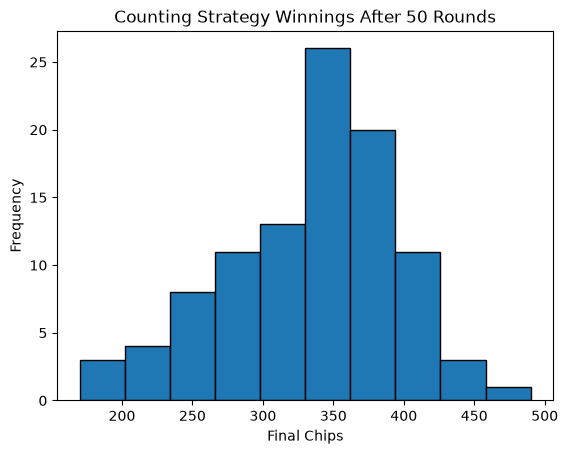

Average final chips: 336.0
Average winnings per round: -3.28
Standard deviation: 61.27
Probability of net win: 0.0
Probability of net loss: 1.0
Probability of breaking even: 0.0


In [35]:
#Question 8

import matplotlib.pyplot as plt
import numpy as np

winnings = []

for i in range(100):
    counting_player = Player("Counting Player", 500, CountingStrategy(-2))

    player1 = Player("Player 1", 500, Strategy("dealer"))
    player2 = Player("Player 2", 500, Strategy("dealer"))
    player3 = Player("Player 3", 500, Strategy("dealer"))

    game = BlackjackGame([counting_player, player1, player2, player3])
    game.simulate(50, verbose=False)

    winnings.append(counting_player.chips)

#Histogram
plt.hist(winnings, bins=10, edgecolor="black")
plt.xlabel("Final Chips")
plt.ylabel("Frequency")
plt.title("Counting Strategy Winnings After 50 Rounds")
plt.show()

#Calculations
average_chips = np.mean(winnings)
average_per_round = (average_chips - 500) / 50
standard_deviation = np.std(winnings)

win_probability = sum(1 for w in winnings if w > 500) / 100
loss_probability = sum(1 for w in winnings if w < 500) / 100
tie_probability = sum(1 for w in winnings if w == 500) / 100

print("Average final chips:", round(average_chips, 2))
print("Average winnings per round:", round(average_per_round, 2))
print("Standard deviation:", round(standard_deviation, 2))
print("Probability of net win:", round(win_probability, 2))
print("Probability of net loss:", round(loss_probability, 2))
print("Probability of breaking even:", round(tie_probability, 2))


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

Threshold: -4 Average winnings: -150.7
Threshold: -2 Average winnings: -163.3
Threshold: 0 Average winnings: -190.5
Threshold: 2 Average winnings: -223.8
Threshold: 4 Average winnings: -262.4

Best threshold: -4
Highest average winnings: -150.7


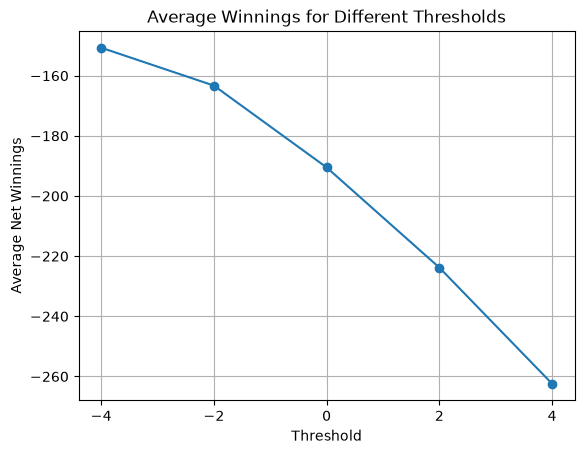

In [36]:
#Question 9

thresholds = [-4, -2, 0, 2, 4]
average_winnings = []
results = {}

for threshold in thresholds:
    winnings = []

    for i in range(100):
        counting_player = Player("Counting Player", 500, CountingStrategy(threshold))
        player1 = Player("Player 1", 500, Strategy("dealer"))
        player2 = Player("Player 2", 500, Strategy("dealer"))
        player3 = Player("Player 3", 500, Strategy("dealer"))

        game = BlackjackGame([counting_player, player1, player2, player3])
        game.simulate(50, verbose=False)

        net_winnings = counting_player.chips - 500
        winnings.append(net_winnings)

    average = np.mean(winnings)
    average_winnings.append(average)
    results[threshold] = average

    print("Threshold:", threshold,
          "Average winnings:", round(average, 2))

best_threshold = max(results, key=results.get)

print("\nBest threshold:", best_threshold)
print("Highest average winnings:", round(results[best_threshold], 2))

#Plot
plt.plot(thresholds, average_winnings, marker="o")
plt.xlabel("Threshold")
plt.ylabel("Average Net Winnings")
plt.title("Average Winnings for Different Thresholds")
plt.xticks(thresholds)
plt.grid(True)
plt.show()

I tested five different thresholds (-4, -2, 0, 2, and 4) by running 100 games of up to 50 rounds for each threshold. Based on my results, -4 performed the best with average net winnings of -150.7 chips. The graph shows that average winnings decreased as the threshold increased. All five thresholds resulted in losses on average but -4 had the smallest loss. This suggests that -4 was the best threshold out of the values I tested but the results could change with more simulations.

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [37]:
#Question 10

class NewStrategy(Strategy):
    def __init__(self):
        super().__init__("new strategy")

    def choose_action(self, hand, dealer_card):
        if hand.get_value() < 16:
            return "h"
        else:
            return "s"

Counting strategy average: -153.8
New strategy average: -27.7
Difference: 126.1
The new strategy performed better.


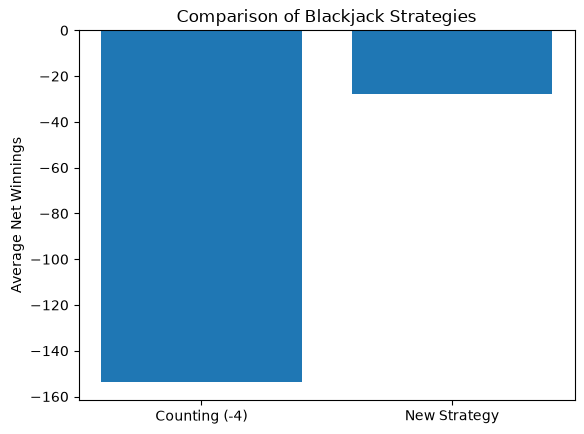

In [38]:
#Test

counting_winnings = []
new_winnings = []

for i in range(100):

    #Counting strategy from Question 9
    counting_player = Player("Counting Player", 500, CountingStrategy(-4))
    player1 = Player("Player 1", 500, Strategy("dealer"))
    player2 = Player("Player 2", 500, Strategy("dealer"))
    player3 = Player("Player 3", 500, Strategy("dealer"))

    game1 = BlackjackGame([counting_player, player1, player2, player3])
    game1.simulate(50, verbose=False)

    counting_winnings.append(counting_player.chips - 500)

    #New strategy
    new_player = Player("New Player", 500, NewStrategy())
    player4 = Player("Player 1", 500, Strategy("dealer"))
    player5 = Player("Player 2", 500, Strategy("dealer"))
    player6 = Player("Player 3", 500, Strategy("dealer"))

    game2 = BlackjackGame([new_player, player4, player5, player6])
    game2.simulate(50, verbose=False)

    new_winnings.append(new_player.chips - 500)

#Compare averages
counting_avg = np.mean(counting_winnings)
new_avg = np.mean(new_winnings)

print("Counting strategy average:", round(counting_avg, 2))
print("New strategy average:", round(new_avg, 2))
print("Difference:", round(new_avg - counting_avg, 2))

if new_avg > counting_avg:
    print("The new strategy performed better.")
elif new_avg < counting_avg:
    print("The new strategy performed worse.")
else:
    print("Both strategies performed the same.")

#Bar graph
plt.bar(["Counting (-4)", "New Strategy"], [counting_avg, new_avg])
plt.ylabel("Average Net Winnings")
plt.title("Comparison of Blackjack Strategies")
plt.show()

For my new strategy, I had the player hit when their hand total was below 16 and stand when it reached 16 or higher. I compared it to the card counting strategy with a threshold of -4 by running 100 games of up to 50 rounds for each strategy. The counting strategy lost an average of 153.8 chips while the new strategy lost an average of 27.7 chips. Overall, the new strategy performed better by 126.1 chips on average. Although both strategies resulted in losses, the new strategy had smaller losses and performed better in my simulation.